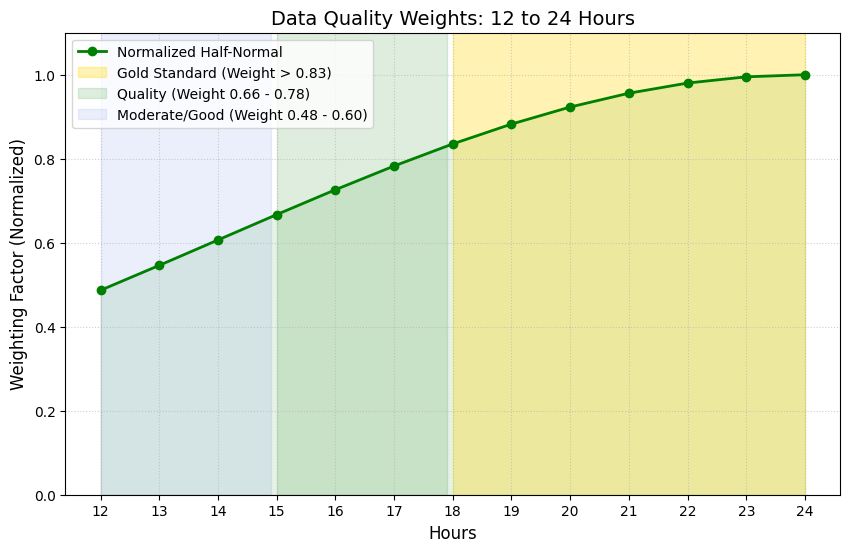

Hour   | Weight     | Quality Category
----------------------------------------
24     | 1.0000     | Gold Standard
23     | 0.9950     | Gold Standard
22     | 0.9802     | Gold Standard
21     | 0.9560     | Gold Standard
20     | 0.9231     | Gold Standard
19     | 0.8825     | Gold Standard
18     | 0.8353     | Gold Standard
17     | 0.7827     | Quality
16     | 0.7261     | Quality
15     | 0.6670     | Quality
14     | 0.6065     | Moderate/Good
13     | 0.5461     | Moderate/Good
12     | 0.4868     | Moderate/Good


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import halfnorm

def plot_quality_weights():
    # 1. Generate the Weighting Logic (Scale = 10)
    ref_hours = np.arange(12, 25)

    # Calculate raw half-normal values peaking at 24
    raw_vals = halfnorm.pdf(24 - ref_hours, loc=0, scale=10)
    max_val = np.max(raw_vals)

    # Create the normalized weights (0.48 to 1.0)
    weights = raw_vals / max_val

    # 2. Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(ref_hours, weights, 'g-o', lw=2, label='Normalized Half-Normal')
    plt.fill_between(ref_hours, weights, color='green', alpha=0.1)

    # Annotate quality zones based on your requirements
    plt.axvspan(18, 24, color='gold', alpha=0.3, label='Gold Standard (Weight > 0.83)')
    plt.axvspan(15, 17.9, color='forestgreen', alpha=0.15, label='Quality (Weight 0.66 - 0.78)')
    plt.axvspan(12, 14.9, color='royalblue', alpha=0.1, label='Moderate/Good (Weight 0.48 - 0.60)')

    # Formatting
    plt.title("Data Quality Weights: 12 to 24 Hours", fontsize=14)
    plt.xlabel("Hours", fontsize=12)
    plt.ylabel("Weighting Factor (Normalized)", fontsize=12)
    plt.xticks(np.arange(12, 25))
    plt.ylim(0, 1.1)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper left')

    plt.show()

    # Print the weights for reference
    print(f"{'Hour':<6} | {'Weight':<10} | {'Quality Category'}")
    print("-" * 40)
    for h, w in zip(reversed(ref_hours), reversed(weights)):
        category = "Gold Standard" if h >= 18 else "Quality" if h >= 15 else "Moderate/Good"
        print(f"{h:<6} | {w:.4f}     | {category}")

# Execute
plot_quality_weights()


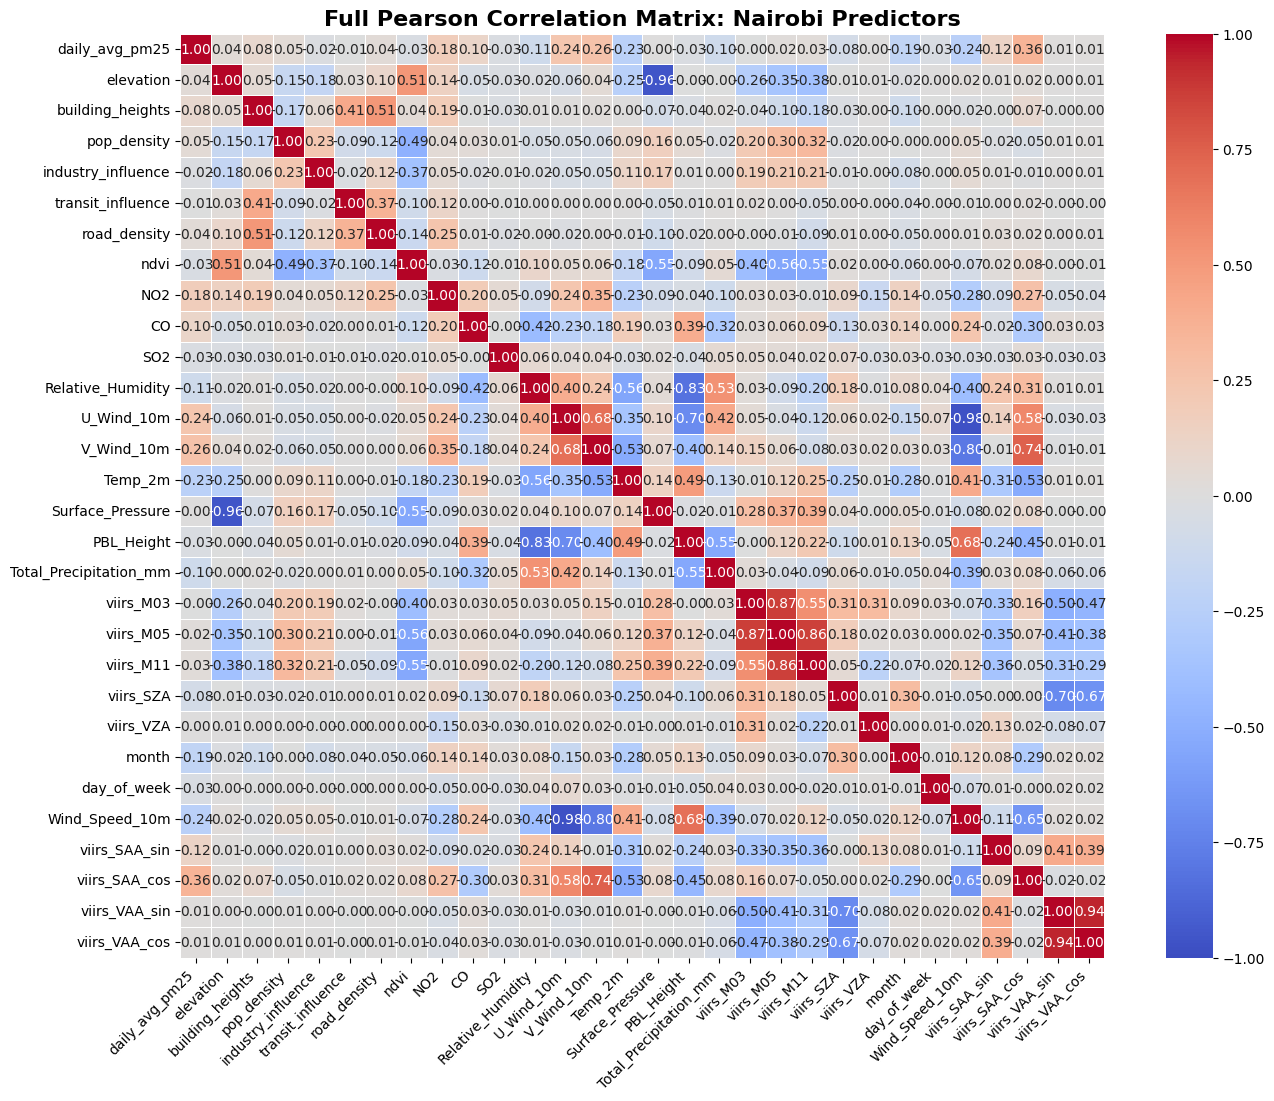

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load your dataset
df = pd.read_csv('/content/nairobi_ml_training_dataset.csv')

# 2. Filter out non-predictive metadata
meta_cols = ['device_name', 'calc_date', 'hours_count', 'latitude', 'longitude',
             'site_id', 'site_name', 'lat', 'lon', 'utm_x', 'utm_y']
features = df.drop(columns=[c for c in meta_cols if c in df.columns])

# 3. Calculate the Correlation
corr_matrix = features.corr(method='pearson')

# 4. Generate the Full Rectangular Heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix,
    annot=True,          # Show the coefficients in the boxes
    fmt=".2f",           # Limit to 2 decimal places
    cmap='coolwarm',     # Standard red-blue diverging color scheme
    vmin=-1, vmax=1,     # Pearson limits
    center=0,
    linewidths=.5,
    square=True          # Ensure cells are perfect squares
)

plt.title('Full Pearson Correlation Matrix: Nairobi Predictors', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.show()

Calculating Mutual Information (this may take a minute)...


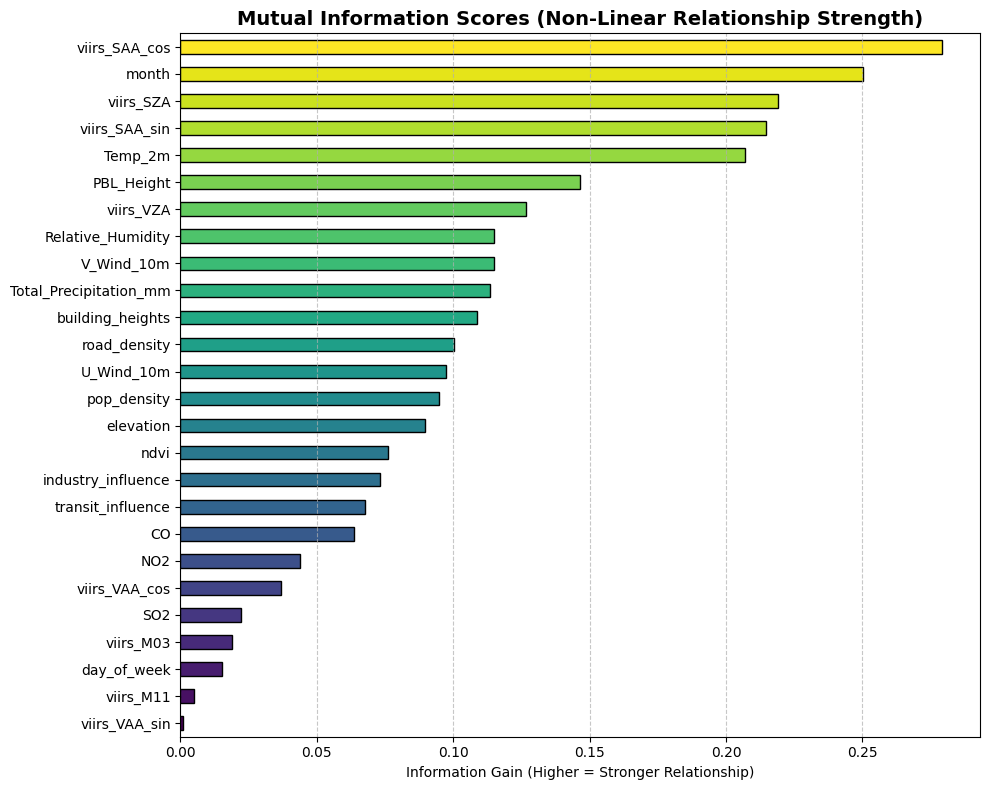


--- Top Information Contributors ---
viirs_SAA_cos             0.279167
month                     0.250199
viirs_SZA                 0.218890
viirs_SAA_sin             0.214486
Temp_2m                   0.206824
PBL_Height                0.146494
viirs_VZA                 0.126826
Relative_Humidity         0.115128
V_Wind_10m                0.114939
Total_Precipitation_mm    0.113481
Name: MI Scores, dtype: float64


In [ ]:
from sklearn.feature_selection import mutual_info_regression
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Load and Clean
df = pd.read_csv('/content/nairobi_ml_cleaned_training_dataset.csv')

# Exclude non-predictive columns
meta_cols = [
    'device_name', 'calc_date', 'hours_count', 'latitude', 'longitude',
    'site_id', 'site_name', 'lat', 'lon', 'utm_x', 'utm_y', 'daily_avg_pm25'
]

X = df.drop(columns=[c for c in meta_cols if c in df.columns], errors='ignore').dropna()
y = df.loc[X.index, 'daily_avg_pm25']

# 2. Calculate Mutual Information
print("Calculating Mutual Information (this may take a minute)...")
# discrete_features=False because your raster/met data is continuous
mi_scores = mutual_info_regression(X, y, random_state=42)

# 3. Organize and Plot
mi_results = pd.Series(mi_scores, name="MI Scores", index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 8))
colors = plt.cm.viridis(np.linspace(0, 1, len(mi_results)))
mi_results.plot(kind='barh', color=colors, edgecolor='black')

plt.title("Mutual Information Scores (Non-Linear Relationship Strength)", fontsize=14, fontweight='bold')
plt.xlabel("Information Gain (Higher = Stronger Relationship)")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Print the top contributors
print("\n--- Top Information Contributors ---")
print(mi_results.sort_values(ascending=False).head(10))


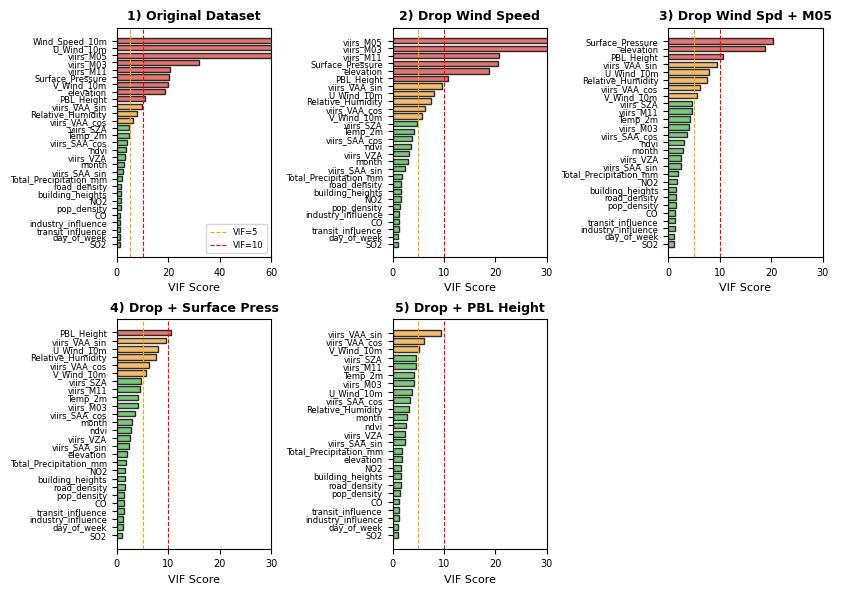

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings("ignore")

# ==========================================
# 1. LOAD DATA & SETTINGS
# ==========================================
df = pd.read_csv('/content/nairobi_ml_training_dataset.csv')

META_COLS = [
    'device_name', 'calc_date', 'hours_count', 'latitude', 'longitude',
    'site_id', 'site_name', 'lat', 'lon', 'utm_x', 'utm_y', 'daily_avg_pm25'
]

# CUMULATIVE drops for a true stepwise VIF reduction
scenarios = [
    {"name": "1) Original Dataset", "drop": []},
    {"name": "2) Drop Wind Speed", "drop": ['Wind_Speed_10m']},
    {"name": "3) Drop Wind Spd + M05", "drop": ['Wind_Speed_10m', 'viirs_M05']},
    {"name": "4) Drop + Surface Press", "drop": ['Wind_Speed_10m', 'viirs_M05', 'Surface_Pressure']},
    {"name": "5) Drop + PBL Height", "drop": ['Wind_Speed_10m', 'viirs_M05', 'Surface_Pressure', 'PBL_Height']}
]

# ==========================================
# 2. A5 OPTIMIZED PLOTTING
# ==========================================
A5_WIDTH_IN = 8.27
A5_HEIGHT_IN = 5.83

fig, axes = plt.subplots(2, 3, figsize=(A5_WIDTH_IN, A5_HEIGHT_IN), constrained_layout=True)
axes = axes.flatten()

for i, scenario in enumerate(scenarios):
    to_drop = META_COLS + scenario['drop']
    X = df.drop(columns=[c for c in to_drop if c in df.columns], errors='ignore').dropna()

    X_const = add_constant(X)
    vif_df = pd.DataFrame()
    vif_df["Feature"] = X_const.columns
    vif_df["VIF"] = [variance_inflation_factor(X_const.values, j) for j in range(X_const.shape[1])]

    vif_df = vif_df[vif_df['Feature'] != 'const'].sort_values(by="VIF", ascending=False)
    vif_df['VIF'] = vif_df['VIF'].replace([np.inf, -np.inf], 999)

    ax = axes[i]
    colors = ['#d9534f' if x > 10 else '#f0ad4e' if x > 5 else '#5cb85c' for x in vif_df['VIF']]
    ax.barh(vif_df['Feature'], vif_df['VIF'], color=colors, edgecolor='black', alpha=0.8, height=0.7)

    ax.axvline(x=5, color='orange', linestyle='--', linewidth=0.8, label='VIF=5')
    ax.axvline(x=10, color='red', linestyle='--', linewidth=0.8, label='VIF=10')

    ax.set_title(scenario['name'], fontsize=9, fontweight='bold')
    ax.invert_yaxis()
    ax.set_xlabel('VIF Score', fontsize=8)

    ax.tick_params(axis='y', labelsize=6)
    ax.tick_params(axis='x', labelsize=7)

    # Scale x-axis dynamically but consistently
    max_vif = vif_df['VIF'].max()
    ax.set_xlim(0, 30 if max_vif < 100 else (60 if max_vif < 500 else 200))

    if i == 0:
        ax.legend(loc='lower right', fontsize=6)

axes[5].axis('off')

plt.savefig('/content/A5_VIF_Analysis_Cumulative.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ==========================================
# 3. EXPORT FINAL CLEANED DATASET
# ==========================================
print("\n--- Generating Final Cleaned Dataset ---")

# The columns identified as highly collinear, excluding PBL_Height as requested
features_to_drop = ['Wind_Speed_10m', 'viirs_M05', 'Surface_Pressure']

# Drop the columns safely
df_cleaned = df.drop(columns=[c for c in features_to_drop if c in df.columns], errors='ignore')

# Define the output path
output_csv_path = '/content/nairobi_ml_cleaned_training_dataset.csv'

# Save the dataset without the index
df_cleaned.to_csv(output_csv_path, index=False)

# Print a summary to the console so you can verify the changes
print(f"Features removed: {features_to_drop}")
print(f"Features retained: PBL_Height and all other original columns.")
print(f"Original dataset shape: {df.shape}")
print(f"Cleaned dataset shape:  {df_cleaned.shape}")
print(f"✅ Successfully saved cleaned data to: {output_csv_path}")


--- Generating Final Cleaned Dataset ---
Features removed: ['Wind_Speed_10m', 'viirs_M05', 'Surface_Pressure']
Features retained: PBL_Height and all other original columns.
Original dataset shape: (17235, 39)
Cleaned dataset shape:  (17235, 36)
✅ Successfully saved cleaned data to: /content/nairobi_ml_cleaned_training_dataset.csv


In [ ]:
df.head()

,device_name,calc_date,daily_avg_pm25,hours_count,latitude,longitude,site_id,site_name,lat,lon,...,viirs_M11,viirs_SZA,viirs_VZA,month,day_of_week,Wind_Speed_10m,viirs_SAA_sin,viirs_SAA_cos,viirs_VAA_sin,viirs_VAA_cos
0,airqo-g5140,2025-02-27,20.100769,13,NaN,36.740052,6448449ac15916001e128cdc,Kuwinda Lang'ata Road,-1.335223,36.74508,...,NaN,26.719999,50.520000,2,3,3.269172,-0.963163,-0.268920,-0.986025,-0.166597
1,airqo-g5140,2025-03-02,38.136111,18,NaN,36.740052,6448449ac15916001e128cdc,Kuwinda Lang'ata Road,-1.335223,36.74508,...,0.100579,13.210000,46.389999,3,6,3.254252,-0.899939,-0.436017,0.988494,0.151261
2,airqo-g5140,2025-03-03,32.569444,18,NaN,36.740052,6448449ac15916001e128cdc,Kuwinda Lang'ata Road,-1.335223,36.74508,...,0.079647,9.000000,63.719997,3,0,3.163697,-0.805618,-0.592435,0.989526,0.144356
3,airqo-g5140,2025-03-04,31.864444,18,NaN,36.740052,6448449ac15916001e128cdc,Kuwinda Lang'ata Road,-1.335223,36.74508,...,NaN,28.109999,56.559998,3,1,3.051015,-0.982353,-0.187038,-0.987933,-0.154883
4,airqo-g5140,2025-03-05,21.562083,24,NaN,36.740052,6448449ac15916001e128cdc,Kuwinda Lang'ata Road,-1.335223,36.74508,...,0.174428,23.480000,33.759998,3,2,3.138250,-0.979329,-0.202275,-0.989425,-0.145047
